# Probe results visualization
Plots outputs from linear probes (age bins) and regression probes (confound features), plus feature-only baselines.


In [12]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')


In [13]:
import os
os.chdir("/Users/tzl/repos/story-features")


## Find artifact files

In [14]:
ROOT = Path('.').resolve()

linear_probe_csvs = sorted(ROOT.glob('artifacts/**/probe_results.csv'))
reg_probe_csvs = sorted(ROOT.glob('artifacts/layerwise_regression_probe/probe_*.csv'))
feature_baselines = sorted(ROOT.glob('artifacts/feature_baseline*.csv'))

print('linear probes:', len(linear_probe_csvs))
for p in linear_probe_csvs[:10]:
    print('  ', p)
print('regression probes:', len(reg_probe_csvs))
for p in reg_probe_csvs[:10]:
    print('  ', p)
print('feature baselines:', len(feature_baselines))
for p in feature_baselines[:10]:
    print('  ', p)


linear probes: 2
   /Users/tzl/repos/story-features/artifacts/linear_probe/probe_results.csv
   /Users/tzl/repos/story-features/artifacts/linear_probe_distilbert/probe_results.csv
regression probes: 5
   /Users/tzl/repos/story-features/artifacts/layerwise_regression_probe/probe_avg_syllables_per_word.csv
   /Users/tzl/repos/story-features/artifacts/layerwise_regression_probe/probe_flesch_kincaid_grade_est.csv
   /Users/tzl/repos/story-features/artifacts/layerwise_regression_probe/probe_mean_log10_corpus_freq.csv
   /Users/tzl/repos/story-features/artifacts/layerwise_regression_probe/probe_rare_frac_corpus_le_5.csv
   /Users/tzl/repos/story-features/artifacts/layerwise_regression_probe/probe_ttr.csv
feature baselines: 1
   /Users/tzl/repos/story-features/artifacts/feature_baseline_batch1_review_samples.csv


## Plot: age-bin linear probe (accuracy vs layer)

In [15]:
if not linear_probe_csvs:
    raise FileNotFoundError('No artifacts/**/probe_results.csv found. Run run_linear_probe.py first.')

# If multiple exist, pick the most recently modified
best = max(linear_probe_csvs, key=lambda p: p.stat().st_mtime)
dfp = pd.read_csv(best)
display(best)
dfp.head()

PosixPath('/Users/tzl/repos/story-features/artifacts/linear_probe_distilbert/probe_results.csv')

,layer,n_train,n_test,n_classes,accuracy,f1_macro
0,0,1326,443,3,0.650113,0.571703
1,1,1326,443,3,0.659142,0.568714
2,2,1326,443,3,0.625282,0.537799
3,3,1326,443,3,0.623025,0.525569
4,4,1326,443,3,0.632054,0.544954


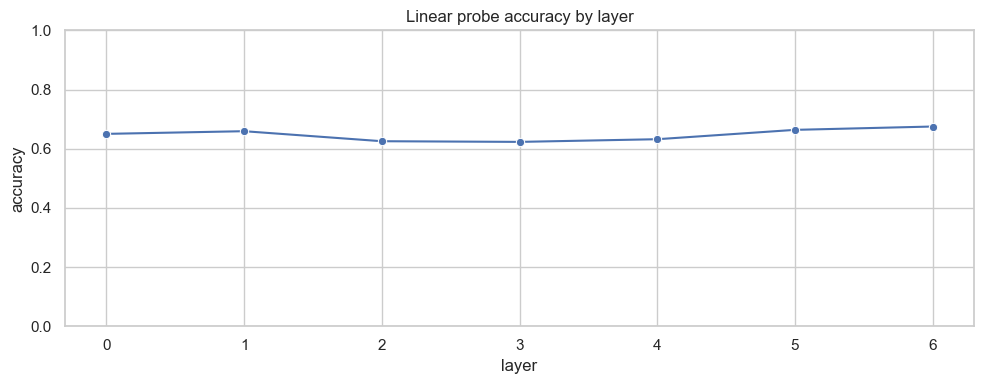

In [16]:
plt.figure(figsize=(10,4))
sns.lineplot(data=dfp, x='layer', y='accuracy', marker='o')
plt.title('Linear probe accuracy by layer')
plt.ylim(0, 1)
plt.tight_layout()


## Plot: regression probes (R² vs layer)

In [17]:
if reg_probe_csvs:
    # Load all and label by target name
    rows=[]
    for p in reg_probe_csvs:
        t = p.stem.replace('probe_','')
        d = pd.read_csv(p)
        d['target'] = t
        d['path'] = str(p)
        rows.append(d)
    reg = pd.concat(rows, ignore_index=True)
    reg.head()
else:
    reg = None
    print('No regression probe CSVs found (artifacts/layerwise_regression_probe/probe_*.csv).')


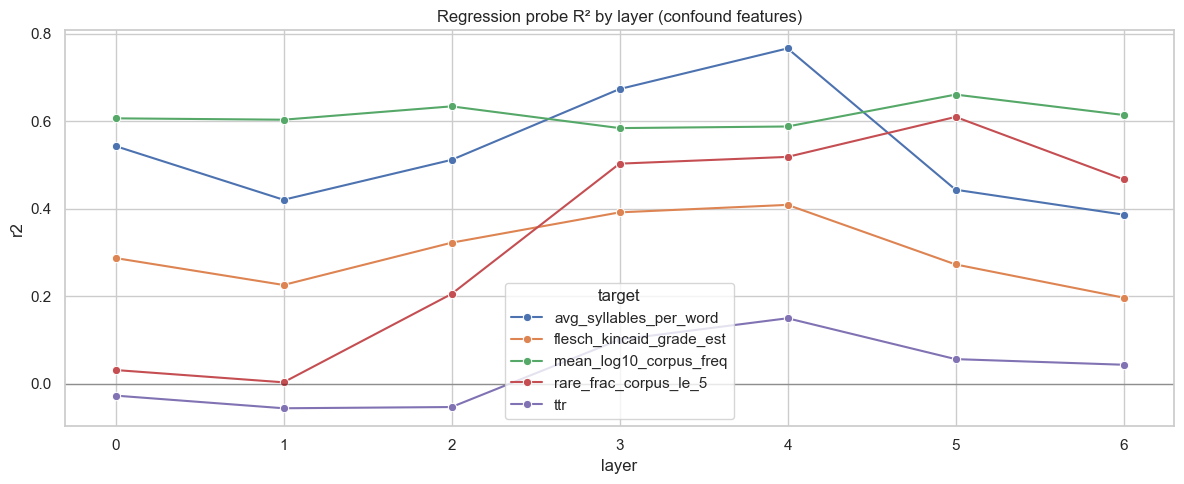

In [18]:
if reg is not None:
    plt.figure(figsize=(12,5))
    sns.lineplot(data=reg, x='layer', y='r2', hue='target', marker='o')
    plt.title('Regression probe R² by layer (confound features)')
    plt.axhline(0, color='black', lw=1, alpha=0.3)
    plt.tight_layout()


## Feature-only baseline (no activations)

In [19]:
if feature_baselines:
    fb = pd.concat([pd.read_csv(p).assign(path=str(p)) for p in feature_baselines], ignore_index=True)
    fb.sort_values('accuracy', ascending=False).head(20)
else:
    print('No artifacts/feature_baseline*.csv found. Run run_feature_baseline_probe.py first.')


## Compare multiple linear probe runs (if present)

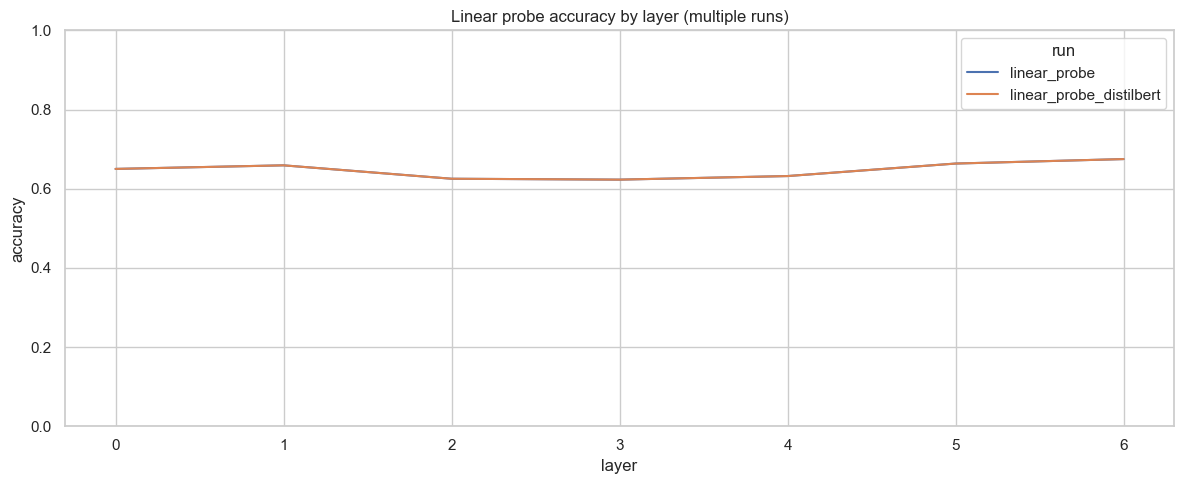

In [20]:
if len(linear_probe_csvs) > 1:
    runs=[]
    for p in linear_probe_csvs:
        d = pd.read_csv(p)
        # label by parent folder
        d['run'] = p.parent.name
        runs.append(d)
    allp = pd.concat(runs, ignore_index=True)
    plt.figure(figsize=(12,5))
    sns.lineplot(data=allp, x='layer', y='accuracy', hue='run')
    plt.title('Linear probe accuracy by layer (multiple runs)')
    plt.ylim(0,1)
    plt.tight_layout()
else:
    print('Only one probe_results.csv found.')
